# Regresión Polinomial

## Fundamentos teóricos

Como sabemos, un análisis de regresión es un conjunto de procesos estadísticos para estimar las relaciones entre una variable dependiente y una o más variables independientes/predictoras.

La regresión polinomial es otro tipo de análisis de regresión. Su enfoque es presentar relaciones No lineales, como curvas.

A diferencia de la regresión múltiple, que se buscan relaciones con más de una o más variables independientes pero con enfoque lineal en forma de hiperplanos, la regresión polinomial busca la relación de una o más variables independientes pero con un enfoque no lineal en forma de planos curvos o superficies curvas.

El modelo se define de esta forma:

$\hat{y} = \beta_0 + \beta_1x + \beta_2x^2 +$...$ \beta_dx^d$

Donde:

* $\hat{y}$ = variable dependiente predecida por el modelo
* $x$ = variable independiente
* $\beta_0$ = punto de intersección con el eje $y$ (grado de libertad)
* $d$ = grado del polinomio
* $\beta_1, \beta_2, ...\beta_d$ = pendientes/coeficientes que el modelo estima apartir de los datos


Nota: Entre más aumente el grado del polinomio, más "flexible" será la curva. No se debe abusar del grado del polinomio hasta tal punto de que el modelo sea tan flexible, que este aproxime a todos los puntos "$x$" del dataset de entrenamiento (overfitting).  




### Función de perdida/error

Para encontrar los coeficientes que forman la curva, se usa el método de mínimos cuadrados, para minimizar las distancias datos-modelo lo más posible.

Función objetivo a minimizar ("$fit()$"):

$\min_{\boldsymbol{\beta}}\sum_{i=1}^{n} (y_i - \hat{y_i})^2$

o bien (sustituyendo $\hat{y_i}$):

$
\boxed{
\min_{\boldsymbol{\beta_0 + \beta_1x + \beta_2x^2 +... \beta_dx^d}}
\sum_{i=1}^{n}(y_i-\beta_0 + \beta_1x + \beta_2x^2 +...\beta_dx^d)^2
}
$



## Pipeline : Regresión Polinomial

### Recolección Limpieza Procesamientos de datos

Convenientemente se tomará un dataset público y datos prácticos.

In [105]:
# importamos librerias
#   Librerias de uso estándar
import numpy as np                # numpy (cálculo numérico/operaciones matemáticas)
import pandas as pd               # pandas (estructurar los datos/filtrar, ordenar, transformar datos, leer data set's)

import matplotlib.pyplot as plt   # matplotlib (gráficos para representar datos)
%matplotlib inline

import seaborn as sns             # seaborn (gráficos estadísticos más avanzados)

#   Librerias propias para la codificación de este modelo
from sklearn.linear_model import LinearRegression  # Clase para aprender los coeficientes.
from sklearn.preprocessing import PolynomialFeatures  # Clase para construir las potencias (hasta x^4 para este caso)
from sklearn.model_selection import train_test_split  # Función para separar datos de entrenamiento y prueba.



In [106]:
# Inicializamos el Dataset
X = [
    [-5], [-4.5], [-4], [-3.5], [-3], [-2.5],
    [-2], [-1.5], [-1], [-0.5], [0],
    [0.5], [1], [1.5], [2], [2.5],
    [3], [3.5], [4], [4.5], [5],
    [5.5], [6], [6.5]
]

y = [
    17.75, 9.33, 4.2, 0.53, -1.45, -2.57,
    -2.2, -1.79, -1.35, -1.68, -1.0,
    -1.69, -1.35, -1.39, -2.2, -2.54,
    -1.45, 0.50, 4.2, 9.38, 17.75,
    23.31, 30.4, 35.3
]

# Spliting (segmentamos el dataset --> datos entrenamiento/prueba )
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=33)  # Reservamos tres posiciones.

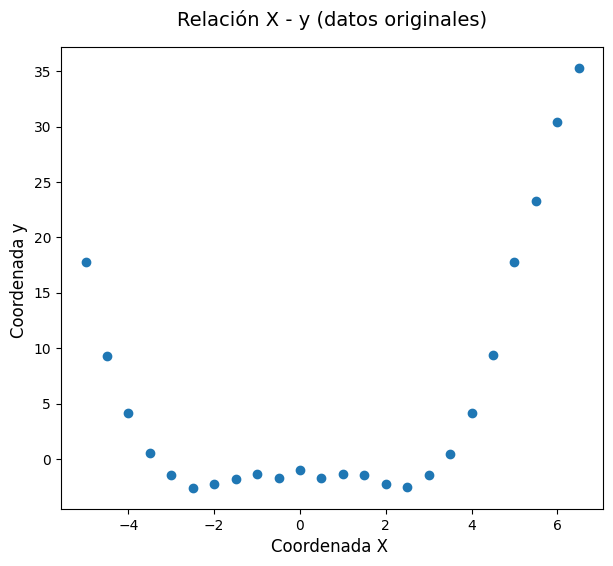

In [107]:
plt.figure(figsize=(7, 6))
# Grafico de dispersión (scatterplot) definición de ejes.
plt.scatter(X, y)

# Etiquetas y título
plt.title('Relación X - y (datos originales)', fontsize=14, pad=15)
plt.xlabel('Coordenada X ', fontsize=12)
plt.ylabel('Coordenada y ', fontsize=12)

plt.show()

### Entrenamiento del modelo de regresión

Creación/definición de objetos

In [108]:
polinomio = PolynomialFeatures(degree=12, include_bias=False)  # Creamos el objeto: grado 4, sin constante duplicada (col. de unos).
modelo = LinearRegression()  # Creamos el objeto que aprenderá la curva de gardo 4

# Entrenamiento (uso de 'fit()')
X_train_poly = polinomio.fit_transform(X_train)  # genera las potenciaciones en datos X necesarias (en este caso: grado 4)
modelo.fit(X_train_poly, y_train)  # Entrenamiento: El método fit aprende solo de los datos de entrenamiento (o sea usamos y_train).

LinearRegression()

Mostramos coeficientes que forman la curva.

* .intercept_ $= \beta_0$
* .coef_[0] $= \beta_1 * x$
* .coef_[1] $= \beta_2 * x^2$
* .coef_[2] $= \beta_3 * x^3$
* .coef_[3] $= \beta_4 * x^4$


In [109]:
print("β0:", round(modelo.intercept_, 4))  # Atributo: intersección (round redondea la salida).
print("β1:", round(modelo.coef_[0], 4))
print("β2:", round(modelo.coef_[1], 4))
print("β3:", round(modelo.coef_[2], 4))
print("β4:", round(modelo.coef_[3], 4))

β0: -1.2176
β1: 0.5614
β2: -0.1546
β3: -0.3586
β4: -0.0515


Mostramos la curva ajustada según los datos de entrenamiento.

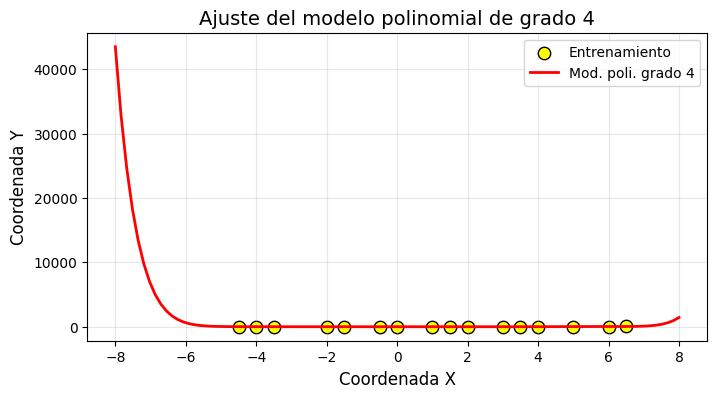

In [110]:
# Creamos lienzo : tamaño pulgadas (ancho, alto)
plt.figure(figsize=(8, 4))

# Aspecto de los datos de entrenamiento
plt.scatter(X_train, y_train, color='yellow', edgecolor='k', s=80, label='Entrenamiento')

# Generar valores continuos de X (linspace) / usamos ".reshape" para convertir ese vector en columna ya que lo requere Scikit-Learn
X_continuo = np.linspace(-8, 8, 100).reshape(-1, 1)

# Transformar X usando el mismo grado del modelo: 4
X_continuo_poly = polinomio.transform(X_continuo)

# Generar/predecir sus valores de "Y"
y_predicho = modelo.predict(X_continuo_poly)

# Dibujar la curva
plt.plot(X_continuo, y_predicho, color='red', linewidth=2, label='Mod. poli. grado 4')

# Configurar gráfica (aspectos propios de la gráfica)
plt.title('Ajuste del modelo polinomial de grado 4', fontsize=14)
plt.xlabel('Coordenada X', fontsize=12)
plt.ylabel('Coordenada Y', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

### Probar el modelo

Gráfica de los datos de prueba.

In [111]:
X_test_poly = polinomio.transform(X_test)  # Preparamos prueba sin volver a ajustar (sin "fit" solo transform).
print("Valores reales:", y_test)
print("Predicciones:", modelo.predict(X_test_poly))  # predict utiliza el modelo aprendido.
print("Para x = 5.7:", modelo.predict(polinomio.transform([[5.7]])))

Valores reales: [-1.69, -2.57, -2.54, -1.45, -1.35, 23.31, 9.38, 17.75]
Predicciones: [-1.02093509 -2.38456305 -2.23333788 -1.75914923 -1.69392292 25.73887578
  9.95174102 29.96975811]
Para x = 5.7: [28.15737028]


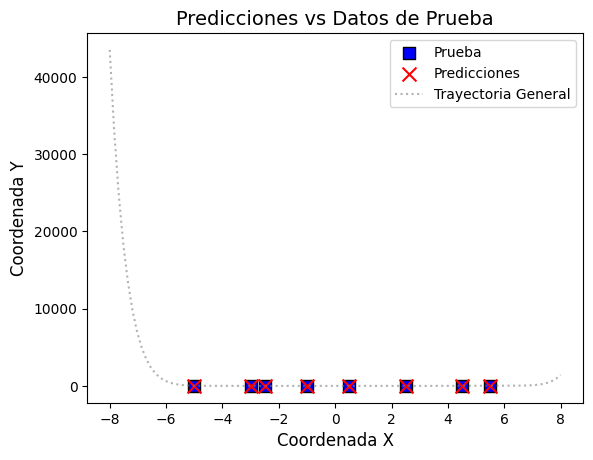

In [112]:

# 1. Transformación de los datos de prueba a características de polinomio de grado 4
X_test_poly = polinomio.transform(X_test)

# 2. Gráfico de los valores originales de Prueba
# marker='s': Usa cuadrados (squares) para diferenciar estos puntos de los de entrenamiento
plt.scatter(X_test, y_test, color='blue', marker='s', edgecolor='k', s=80, label='Prueba')

# 3. Gráfico de las Predicciones
# Predecimos directamente y graficamos.
# marker='x': Dibuja cruces para las predicciones exactas
plt.scatter(X_test, modelo.predict(X_test_poly), color='red', marker='x', s=100, label='Predicciones')

# 4. Curva de referencia visual
# alpha=0.6: Aplica transparencia del 60% para que la línea quede en segundo plano
# linestyle=':': Dibuja una línea punteada fina
plt.plot(X_continuo, modelo.predict(polinomio.transform(X_continuo)), color='gray', linewidth=1.5, linestyle=':', alpha=0.6, label='Trayectoria General')

# 5. Configuración de etiquetas y leyenda
plt.title('Predicciones vs Datos de Prueba', fontsize=14)
plt.xlabel('Coordenada X', fontsize=12)
plt.ylabel('Coordenada Y', fontsize=12)
plt.legend()

plt.show()

### Métricas de evaluación

#### Coeficiente de determinación ($R^2$)

Esta métrica dice que el modelo logra reproducir o representar una parte de la variación que se observa en los valores reales.


$$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$$

* Si $R^2 = 1 $ : las predicciones coinciden perfectamente con los valores observados.
* $R^2 ≈ 0 $ : el modelo no obtiene una mejora sobre esa referencia (o sea la media)
* $R^2 < 0 $ : Además de no mejorar la forma en la que hacemos predicciones, este enfoque es peor.


In [113]:
# Importamos la función para calcular el coeficiente de determinación
from sklearn.metrics import r2_score

# 1. Predicciones sobre el conjunto de entrenamiento
# (Asumiendo que X_train_poly fue creado durante la fase de entrenamiento)
y_train_pred = modelo.predict(X_train_poly)

# 2. Predicciones sobre el conjunto de prueba
# (Usamos X_test_poly creado en la celda anterior)
y_test_pred = modelo.predict(X_test_poly)

# 3. Cálculo de la métrica R² para ambos conjuntos
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

# 4. Impresión de resultados
print("------ Evaluación del Modelo Cuadrático -----")
print(f"R² en Entrenamiento: {r2_train:.4f}")
print(f"R² en Prueba:        {r2_test:.4f}")

------ Evaluación del Modelo Cuadrático -----
R² en Entrenamiento: 0.9999
R² en Prueba:        0.7937


#### Error cuadrático medio (MSE)

**¿Cuál es el error promedio si hago que los errores grandes tengan mucha menos influencia?** Esta métrica nos ayuda a responer esta preguna. Es una métrica de "pérdida": cuanto menor sea el valor, mejor será el modelo, siendo  0.0  el escenario de un ajuste perfecto (sin errores).


$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

* Penaliza mucho más los errores grandes.
* Además de medir el error promedio, castiga especialmente los errores grandes.


In [114]:
# Importamos la métrica directamente de Scikit-Learn
from sklearn.metrics import mean_squared_error

# Calculamos el MSE pasando primero los valores reales y luego las predicciones
# Nota: Reutilizamos y_train_pred y y_test_pred calculados en la celda del R^2
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)

# Imprimimos los resultados con 4 decimales de precisión para mayor claridad
print("=== Evaluación del Modelo: MSE ===")
print(f"MSE en Entrenamiento: {mse_train:.4f}")
print(f"MSE en Prueba:        {mse_test:.4f}")

=== Evaluación del Modelo: MSE ===
MSE en Entrenamiento: 0.0115
MSE en Prueba:        19.5423
